# Gradient Descent with Momentum — Retail Profit Prediction

## Project overview
This notebook uses the Sample Superstore dataset to predict **Profit** from **Sales**, **Quantity**, and **Discount** using degree-2 Polynomial Regression.

The optimizer is implemented manually with NumPy: **Batch Gradient Descent with Momentum**. The same train/test split and preprocessing should be kept when comparing it with the other optimizers.

**Target:** `Profit`  
**Input features:** `Sales`, `Quantity`, `Discount`  
**Polynomial degree:** 2

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load the dataset

In [2]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv("Sample - Superstore.csv", encoding="cp1252")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Saving Sample - Superstore.csv to Sample - Superstore.csv
Dataset loaded successfully!
Dataset Shape: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


## 3. Explore and check data quality

This cell displays column types, missing values, duplicate rows, and descriptive statistics.

In [3]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nStatistical Summary:")
df.describe()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


## 4. Select features and split the data

We use 80% of the records for training and 20% for testing.

In [4]:
X = df[['Sales', 'Quantity', 'Discount']]

y = df['Profit']

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 7995
Testing samples: 1999


## 5. Generate polynomial features

Degree 2 adds squared terms and pairwise interactions so the model can learn nonlinear relationships.

In [5]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

print("Original Features:", X_train.shape[1])
print("Polynomial Features:", X_train_poly.shape[1])

print("Polynomial Feature Names:")
print(poly.get_feature_names_out(['Sales', 'Quantity', 'Discount']))

Original Features: 3
Polynomial Features: 10
Polynomial Feature Names:
['1' 'Sales' 'Quantity' 'Discount' 'Sales^2' 'Sales Quantity'
 'Sales Discount' 'Quantity^2' 'Quantity Discount' 'Discount^2']


## 6. Normalize the input features

Normalization parameters are calculated from the training set only, then applied to both sets to avoid data leakage.

In [6]:
mean = X_train_poly.mean(axis=0)
range_values = X_train_poly.max(axis=0) - X_train_poly.min(axis=0)

# Avoid division by zero
range_values[range_values == 0] = 1

# Apply Mean Normalization
X_train_norm = (X_train_poly - mean) / range_values
X_test_norm = (X_test_poly - mean) / range_values

# Keep the bias column unchanged
X_train_norm[:, 0] = 1
X_test_norm[:, 0] = 1

print("Normalization completed successfully!")
print("Training shape:", X_train_norm.shape)
print("Testing shape:", X_test_norm.shape)

Normalization completed successfully!
Training shape: (7995, 10)
Testing shape: (1999, 10)


## 7. Scale the target variable

The target is standardized using the training-set mean and standard deviation. Predictions are converted back to the original Profit scale during evaluation.

In [7]:
y_mean = y_train.mean()
y_std = y_train.std()

y_train_scaled = (y_train.to_numpy() - y_mean) / y_std
y_test_scaled = (y_test.to_numpy() - y_mean) / y_std

print("Target scaling completed!")

Target scaling completed!


## 8. Train using Batch Gradient Descent with Momentum

At each epoch, the gradient is calculated using the **entire training set**. Momentum combines the current gradient with the previous update to help smooth and accelerate optimization.

In [8]:
# Convert data to NumPy arrays
X = X_train_norm
y = y_train_scaled

# Initialize parameters
m, n = X.shape
W = np.zeros(n)
V = np.zeros(n)

# Hyperparameters
learning_rate = 0.01
momentum = 0.9
epochs = 1000

loss_history = []

# Gradient Descent with Momentum
for epoch in range(epochs):

    # Prediction
    y_pred = X @ W

    # Calculate Loss
    loss = np.sum((y_pred - y) ** 2) / (2 * m)
    loss_history.append(loss)

    # Calculate Gradient
    gradient = (X.T @ (y_pred - y)) / m

    # Update Momentum
    V = momentum * V + gradient

    # Update Weights
    W = W - learning_rate * V

# Recalculate loss using the final weights after the last update
final_predictions = X @ W
final_loss = np.sum((final_predictions - y) ** 2) / (2 * m)

print("Gradient Descent Training Completed!")
print("Final Loss:", final_loss)

Gradient Descent Training Completed!
Final Loss: 0.40654858535215804


## 9. Visualize the training loss

A decreasing loss curve indicates that the optimizer is learning from the training data.

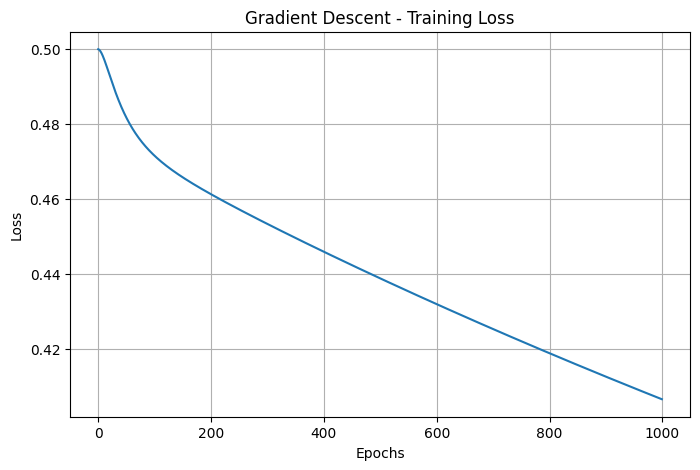

In [9]:
plt.figure(figsize=(8, 5))

plt.plot(loss_history)

plt.title("Gradient Descent - Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.grid()
plt.show()

## 10. Evaluate the model

The metrics are calculated on the unseen test set. R² indicates how much of the variation in Profit is explained by the model.

In [10]:
# Make predictions on test data
y_pred_scaled = X_test_norm @ W

# Convert predictions back to original scale
y_pred = y_pred_scaled * y_std + y_mean

# Calculate evaluation metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Gradient Descent Results")
print("------------------------")
print("MSE:", mse)
print("RMSE:", rmse)
print("MAE:", mae)
print("R2 Score:", r2)

Gradient Descent Results
------------------------
MSE: 44086.2004484165
RMSE: 209.96714135410926
MAE: 67.16966135344205
R2 Score: 0.09072731576407145


## 11. Results and interpretation

In the previously recorded run, the test metrics were approximately:

- **RMSE:** 209.97
- **MAE:** 67.17
- **R²:** 0.0907

The R² value means that this model explained about 9.07% of the variation in test-set Profit in that run. This is relatively low, so the model has room for improvement. Compare the optimizers using the same data split and preprocessing; do not assume that a lower training loss alone means better test performance.

> Note: Re-run the notebook from top to bottom in Google Colab after uploading the CSV file. The data-inspection cell and the updated final-loss cell need fresh execution outputs.